# Replicating *Efficient Selection of Investment Portfolios in Real-World Markets* with pymoo

Hidalgo-Marín, Nebro & García-Nieto, *Algorithms* **2026**, 19, 20 — [doi:10.3390/a19010020](https://doi.org/10.3390/a19010020)

This notebook re-runs the paper's experiment with **pymoo** instead of jMetal, using its three evolutionary algorithms: **NSGA-II**, **MOEA/D** and **SMS-EMOA**. SMPSO is left out.

| Step | Paper |
|---|---|
| 1. Download the authors' return vectors and covariance matrices | §4, §5.2 |
| 2. Define the bi-objective portfolio problem and its encoding | §3 |
| 3. Run each algorithm with the Table 3 settings | §5.1, §5.3 |
| 4. Quality indicators IGD+ and HV, Wilcoxon tests, CD plots | §6.1, Tables 4–7, Figs. 2–3 |
| 5. Pareto-front figures | Figs. 4–6 |
| 6. Representative portfolios | §6.3, Tables 8–14 |

**Where this follows the authors' released code rather than the paper text.** These points were checked against the solutions they published, and §2 reproduces those solutions exactly:
- A solution has **2k** variables, not 2N: k asset pointers followed by k weights, one weight per selected slot.
- "Risk" is the **annualised volatility** $\sqrt{250\,w^\top\Sigma w}$, not the variance written in Eq. (1). This is the quantity on the axes of the paper's figures and in its tables.
- Weights are repaired (normalised and bounded) and written back into the solution, as in their stored results.

## 0. Settings

The paper's values are in the comments. With the defaults, all 12 instances and 10 runs per algorithm, the runs take about **an hour** (63 min measured on a 6-core / 12-thread machine), plus a few minutes of downloads the first time. Finished runs are cached in `data/processed/`, so re-running the notebook only computes what is missing. For example, raising `N_RUNS` to the paper's 30 only runs the 20 extra runs. `ALL_20_3000` and `ALL_20_6000` need about 320 MB of downloads, and their covariance files are 0.2 GB and 0.8 GB as CSV. Drop them from `INSTANCES` for a much quicker run.

In [1]:
import io
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats

from pymoo.algorithms.moo.moead import MOEAD
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.sms import SMSEMOA
from pymoo.core.problem import Problem
from pymoo.core.repair import Repair
from pymoo.decomposition.pbi import PBI
from pymoo.indicators.hv import HV
from pymoo.indicators.igd_plus import IGDPlus
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.optimize import minimize
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from pymoo.util.ref_dirs import get_reference_directions

INSTANCES = [
    "NYSE_5_100", "NASDAQ_5_100", "OTC_5_100", "AMEX_5_100", "ARCA_5_100", "BATS_5_100", "ALL_5_100",
    "ALL_20_100", "ALL_20_500", "ALL_20_1000", "ALL_20_3000", "ALL_20_6000",
]
ALGORITHMS = ["MOEA/D", "SMS-EMOA", "NSGA-II"]  # same column order as the paper's tables
N_RUNS = 10            # paper: 30 independent runs
POP_SIZE = 100         # paper: 100 individuals
BASE_EVALS = 50_000    # paper: 50,000 evaluations for the *_100 instances,
EVAL_MULTIPLIER = {"ALL_20_500": 2, "ALL_20_1000": 3, "ALL_20_3000": 4, "ALL_20_6000": 5}  # x2..x5 for larger ones
EVAL_SCALE = 1.0       # e.g. 0.1 for a quick smoke test
SEED = 12345           # paper: fixed seed 12345 (run r uses SEED + r)
RISK_FREE = 0.0697     # paper: Rf = 6.97 %
TRADING_DAYS = 250     # annualisation factor used by the authors' code
N_JOBS = -1            # worker processes for the runs (-1 = all cores)


def n_evals(instance):
    return int(BASE_EVALS * EVAL_MULTIPLIER.get(instance, 1) * EVAL_SCALE)


ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROCESSED, FIGURES = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "reports" / "figures"
for folder in (RAW, PROCESSED, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# One fixed colour per algorithm in every figure.
COLORS = {"NSGA-II": "#2a78d6", "MOEA/D": "#eb6834", "SMS-EMOA": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.spines.top": False, "axes.spines.right": False,
})

## 1. Data (§4, §5.2)

The authors publish their inputs and results in a single 367 MB release zip ([Portfolio_Study_DataSources](https://github.com/AntHidMar/Portfolio_Study_DataSources/releases/tag/financial_data)). The notebook reads only the files it needs, using HTTP range requests, and saves them to `data/raw/`. For each instance that is:
- the return of every asset in the universe (sorted from best to worst),
- the covariance matrix of daily returns,
- the paper's reference front, which merges all four algorithms including SMPSO. It is only used for comparison in the figures.

In [2]:
ZIP_URL = ("https://github.com/AntHidMar/Portfolio_Study_DataSources/"
           "releases/download/financial_data/Portfolio_Study.zip")


class RemoteFile(io.RawIOBase):
    """Seekable, read-only view of a remote file that downloads only the byte ranges read."""

    def __init__(self, url):
        self.url, self.pos = url, 0
        with urllib.request.urlopen(urllib.request.Request(url, method="HEAD"), timeout=60) as r:
            self.size = int(r.headers["Content-Length"])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=io.SEEK_SET):
        self.pos = {io.SEEK_SET: 0, io.SEEK_CUR: self.pos, io.SEEK_END: self.size}[whence] + offset
        return self.pos

    def read(self, n=-1):
        end = self.size if n is None or n < 0 else min(self.pos + n, self.size)
        if end <= self.pos:
            return b""
        request = urllib.request.Request(self.url, headers={"Range": f"bytes={self.pos}-{end - 1}"})
        for attempt in range(3):
            try:
                with urllib.request.urlopen(request, timeout=120) as r:
                    data = r.read()
                break
            except OSError:
                if attempt == 2:
                    raise
                time.sleep(2)
        self.pos += len(data)
        return data


def fetch_from_release(files):
    """Extract {local path: path inside the zip} for the files not downloaded yet."""
    missing = {dest: member for dest, member in files.items() if not dest.exists()}
    if not missing:
        return
    with zipfile.ZipFile(RemoteFile(ZIP_URL)) as z:
        for dest, member in missing.items():
            print(f"downloading {member} ({z.getinfo(member).compress_size / 1e6:.1f} MB)")
            tmp = dest.with_suffix(".part")
            with z.open(member) as src, open(tmp, "wb") as dst:
                shutil.copyfileobj(src, dst, 8 << 20)
            tmp.replace(dest)


def raw_path(instance, kind):
    return RAW / f"{instance}_{kind}.csv"


def download_instances(instances):
    files = {}
    for inst in instances:
        files[raw_path(inst, "mean_return")] = f"Portfolio_Study/sources/{inst}/_mean_hist_return.csv"
        files[raw_path(inst, "covariance")] = f"Portfolio_Study/sources/{inst}/_cov_hist_return.csv"
        files[raw_path(inst, "paper_reference_front")] = f"Portfolio_Study/referenceFronts/{inst}.csv"
    fetch_from_release(files)


def load_instance(instance, with_cov=True):
    mu = pd.read_csv(raw_path(instance, "mean_return"), index_col=0).iloc[:, 0]
    cov = None
    if with_cov:
        cov_df = pd.read_csv(raw_path(instance, "covariance"), index_col=0)
        assert list(cov_df.index) == list(cov_df.columns) == list(mu.index), "assets out of order"
        cov = cov_df.to_numpy()
    assets = [s.rsplit("\\", 1)[-1].removeprefix("Day_") for s in mu.index]
    return {"k": int(instance.split("_")[1]), "mu": mu.to_numpy(), "cov": cov, "assets": assets}


download_instances(INSTANCES)

pd.DataFrame(
    [{"instance": inst,
      "universe size N": len(load_instance(inst, with_cov=False)["mu"]),
      "portfolio size k": int(inst.split("_")[1]),
      "evaluations per run": n_evals(inst)} for inst in INSTANCES]
).set_index("instance")

,universe size N,portfolio size k,evaluations per run
instance,,,
NYSE_5_100,100,5,50000
NASDAQ_5_100,100,5,50000
OTC_5_100,100,5,50000
AMEX_5_100,100,5,50000
ARCA_5_100,100,5,50000
BATS_5_100,100,5,50000
ALL_5_100,100,5,50000
ALL_20_100,100,20,50000
ALL_20_500,500,20,100000


## 2. Problem formulation and encoding (§3)

Two objectives, both minimised:

$$f_1 = \text{risk} = \sqrt{250\; w^\top \Sigma_S\, w}, \qquad f_2 = -\text{return} = -\sum_{j \in S} w_j R_j$$

where $S$ is the set of $k$ selected assets, $\Sigma_S$ their covariance block and $w$ their weights.

**Encoding (§3.2).** A solution is $x = (s_1,\dots,s_k,\; v_1,\dots,v_k)$:
1. **Selection.** Each $s_i \in [0,1]$ points to asset $\lfloor s_i N \rfloor$. If that asset is already taken, it moves to the next free one, wrapping around (linear probing, Eq. 3).
2. **Weights.** $v_i$ is the raw weight of the $i$-th selected asset. Weights are normalised to sum to 1 and kept inside $[\tfrac{1}{2k},\, \tfrac{2}{k}]$ (Eq. 4). A single scale factor $\lambda$ is found so that $\sum_i \operatorname{clip}(\lambda v_i)$ equals 1. The repaired weights replace the $v_i$, which is how the authors' stored solutions look.

In [3]:
def decode_assets(S, n_assets):
    """Selection part -> asset indices, with linear probing on collisions (§3.2.1)."""
    n, k = S.shape
    rows = np.arange(n)
    taken = np.zeros((n, n_assets), dtype=bool)
    assets = np.empty((n, k), dtype=int)
    for j in range(k):
        c = np.minimum((S[:, j] * n_assets).astype(int), n_assets - 1)
        clash = taken[rows, c]
        while clash.any():
            c[clash] = (c[clash] + 1) % n_assets
            clash = taken[rows, c]
        taken[rows, c] = True
        assets[:, j] = c
    return assets


def bound_weights(W, w_min, w_max):
    """Normalise each row to sum 1 with every weight in [w_min, w_max].

    Finds lambda with sum(clip(lambda * w, w_min, w_max)) = 1 exactly: the sum is piecewise linear
    in lambda with breakpoints w_min / w_i and w_max / w_i, so it is solved on that segment.
    """
    W = W / W.sum(axis=1, keepdims=True)
    breaks = np.sort(np.concatenate([w_min / W, w_max / W], axis=1), axis=1)
    total = np.clip(breaks[:, :, None] * W[:, None, :], w_min, w_max).sum(axis=2)
    j = np.clip((total < 1).sum(axis=1), 1, breaks.shape[1] - 1)
    r = np.arange(len(W))
    l0, l1, t0, t1 = breaks[r, j - 1], breaks[r, j], total[r, j - 1], total[r, j]
    lam = l0 + (1 - t0) * (l1 - l0) / np.maximum(t1 - t0, 1e-300)
    return np.clip(lam[:, None] * W, w_min, w_max)


class PortfolioProblem(Problem):
    """Minimise (risk, -return) of a k-asset portfolio drawn from N assets (§3.1)."""

    def __init__(self, mu, cov, k):
        self.mu, self.cov, self.k, self.n_assets = mu, cov, k, len(mu)
        self.w_min, self.w_max = 1 / (2 * k), 2 / k  # Eq. (4)
        super().__init__(
            n_var=2 * k, n_obj=2,
            xl=np.r_[np.zeros(k), np.full(k, self.w_min)],
            xu=np.r_[np.ones(k), np.full(k, self.w_max)],
        )

    def _evaluate(self, X, out, *args, **kwargs):
        assets = decode_assets(X[:, : self.k], self.n_assets)
        w = X[:, self.k :]
        expected_return = np.sum(w * self.mu[assets], axis=1)
        variance = np.einsum("ni,nij,nj->n", w, self.cov[assets[:, :, None], assets[:, None, :]], w)
        out["F"] = np.column_stack([np.sqrt(TRADING_DAYS * variance), -expected_return])


class WeightRepair(Repair):
    """Write the normalised, bounded weights back into the solution before evaluation."""

    def _do(self, problem, X, **kwargs):
        X = X.copy()
        X[:, problem.k :] = bound_weights(X[:, problem.k :], problem.w_min, problem.w_max)
        return X


# The paper's worked example (§3.2.2): N = 4 assets A-D, k = 2, x = [0.20, 0.22 | 0.5, 0.4]
print("assets:", decode_assets(np.array([[0.20, 0.22]]), 4)[0],
      "  weights:", bound_weights(np.array([[0.5, 0.4]]), 1 / 4, 2 / 2)[0].round(2))

assets: [0 1]   weights: [0.56 0.44]


**Check against the authors' published solutions.** The release contains the decision vectors behind each algorithm's reference front together with their objective values. Evaluating their NSGA-II solutions for AMEX_5_100 with the problem above should give back the same objectives.

In [4]:
download_instances(["AMEX_5_100"])
fetch_from_release({
    RAW / "AMEX_5_100_paper_NSGAII_X.csv": "Portfolio_Study/referenceFronts/AMEX_5_100.NSGAII.rs",
    RAW / "AMEX_5_100_paper_NSGAII_F.csv": "Portfolio_Study/referenceFronts/AMEX_5_100.NSGAII.rf",
})
amex = load_instance("AMEX_5_100")
X_paper = np.loadtxt(RAW / "AMEX_5_100_paper_NSGAII_X.csv", delimiter=",")
F_paper = np.loadtxt(RAW / "AMEX_5_100_paper_NSGAII_F.csv", delimiter=",")
F_ours = PortfolioProblem(amex["mu"], amex["cov"], amex["k"]).evaluate(X_paper, return_values_of=["F"])
print(f"{len(X_paper)} published solutions, {X_paper.shape[1]} variables each; "
      f"largest objective difference: {np.abs(F_ours - F_paper).max():.1e}")

199 published solutions, 10 variables each; largest objective difference: 7.7e-15


## 3. Algorithms (§5.1, Table 3)

| Setting | Paper (jMetal) | Here (pymoo) |
|---|---|---|
| Population | 100 | `pop_size=100`; MOEA/D gets 100 uniform weight vectors |
| Mutation | polynomial, $p_m = 1/n$, $\eta_m = 20$ | `PM(prob=1.0, eta=20)`; pymoo's per-variable probability defaults to $1/n$ |
| Crossover (all three) | SBX, $p_c = 0.9$, $\eta_c = 20$ | `SBX(prob=0.9, eta=20)` |
| MOEA/D | PBI ($\theta = 5$), $T = 20$, $\delta = 0.9$, $n_r = 2$, no normalisation | `PBI(theta=5)`, `n_neighbors=20`, `prob_neighbor_mating=0.9`. pymoo has no $n_r$, so the subclass below adds it |
| SMS-EMOA | steady state | `n_offsprings=1` (one offspring per iteration) |

Two small subclasses:
- **`MOEADLimitedReplacement`.** pymoo's MOEA/D replaces *every* neighbour the offspring improves on. The paper caps this at $n_r = 2$, checking neighbours in random order.
- **`LazyOptimum`.** pymoo re-computes the non-dominated set after every generation. The result does not need it, since the final front is extracted at the end as jMetal does, and skipping it makes the steady-state SMS-EMOA about 30 % faster.

jMetal does not remove duplicate solutions, so duplicate elimination is switched off here too.

In [5]:
class LazyOptimum:
    def _set_optimum(self):
        self.opt = self.pop


class NSGA2Lazy(LazyOptimum, NSGA2):
    pass


class SMSEMOALazy(LazyOptimum, SMSEMOA):
    pass


class MOEADLimitedReplacement(LazyOptimum, MOEAD):
    def __init__(self, *args, nr=2, **kwargs):
        super().__init__(*args, **kwargs)
        self.nr = nr

    def _replace(self, k, off):
        neighbors = self.random_state.permutation(self.neighbors[k])
        weights = self.ref_dirs[neighbors]
        current = self.decomposition.do(self.pop[neighbors].get("F"), weights=weights, ideal_point=self.ideal)
        candidate = self.decomposition.do(off.F[None, :], weights=weights, ideal_point=self.ideal)
        better = np.flatnonzero(candidate < current)[: self.nr]
        self.pop[neighbors[better]] = off


def make_algorithm(name):
    common = dict(crossover=SBX(prob=0.9, eta=20), mutation=PM(prob=1.0, eta=20), repair=WeightRepair())
    if name == "NSGA-II":
        return NSGA2Lazy(pop_size=POP_SIZE, eliminate_duplicates=False, **common)
    if name == "MOEA/D":
        return MOEADLimitedReplacement(
            ref_dirs=get_reference_directions("uniform", 2, n_partitions=POP_SIZE - 1),
            n_neighbors=20, prob_neighbor_mating=0.9, decomposition=PBI(theta=5.0), nr=2, **common,
        )
    if name == "SMS-EMOA":
        return SMSEMOALazy(pop_size=POP_SIZE, n_offsprings=1, eliminate_duplicates=False, **common)
    raise ValueError(name)

## 4. Runs (§5.3)

Every (instance, algorithm, run) is an independent job, and run `r` uses seed `SEED + r`. Jobs run in parallel and the longest go first. Each run keeps the non-dominated solutions of its final population. Those are appended to `data/processed/pymoo_<instance>_<algorithm>_<evals>evals.csv` as soon as the run finishes, so an interrupted experiment resumes where it stopped.

In [6]:
def cache_path(instance, algorithm):
    slug = algorithm.replace("/", "").replace("-", "")
    return PROCESSED / f"pymoo_{instance}_{slug}_{n_evals(instance)}evals.csv"


def finished_runs(instance, algorithm):
    path = cache_path(instance, algorithm)
    return set(pd.read_csv(path, usecols=["run"])["run"]) if path.exists() else set()


def run_once(instance, algorithm, run, data, n_eval):
    problem = PortfolioProblem(data["mu"], data["cov"], data["k"])
    res = minimize(problem, make_algorithm(algorithm), ("n_eval", n_eval), seed=SEED + run, verbose=False)
    F, X = res.pop.get("F"), res.pop.get("X")
    front = NonDominatedSorting().do(F, only_non_dominated_front=True)
    return instance, algorithm, run, F[front], X[front]


def save_run(instance, algorithm, run, F, X):
    k = X.shape[1] // 2
    df = pd.DataFrame(X, columns=[f"s{j}" for j in range(k)] + [f"w{j}" for j in range(k)])
    df.insert(0, "neg_return", F[:, 1])
    df.insert(0, "risk", F[:, 0])
    df.insert(0, "run", run)
    path = cache_path(instance, algorithm)
    df.to_csv(path, mode="a", header=not path.exists(), index=False)


RELATIVE_COST = {"NSGA-II": 1, "MOEA/D": 17, "SMS-EMOA": 23}  # measured seconds per run, relative
todo = [(inst, alg, r) for inst in INSTANCES for alg in ALGORITHMS
        for r in range(N_RUNS) if r not in finished_runs(inst, alg)]
todo.sort(key=lambda t: -n_evals(t[0]) * RELATIVE_COST[t[1]])
print(f"{len(todo)} of {len(INSTANCES) * len(ALGORITHMS) * N_RUNS} runs still to do")

if todo:
    start = time.time()
    data = {inst: load_instance(inst) for inst in sorted({t[0] for t in todo})}
    remaining = pd.Series([(i, a) for i, a, _ in todo]).value_counts().to_dict()
    jobs = (delayed(run_once)(inst, alg, r, data[inst], n_evals(inst)) for inst, alg, r in todo)
    for inst, alg, r, F, X in Parallel(n_jobs=N_JOBS, return_as="generator_unordered")(jobs):
        save_run(inst, alg, r, F, X)
        remaining[inst, alg] -= 1
        if remaining[inst, alg] == 0:
            print(f"{(time.time() - start) / 60:6.1f} min  {inst:<13} {alg:<9} done")
    del data
    print(f"all runs finished in {(time.time() - start) / 60:.1f} min")

0 of 360 runs still to do


## 5. Quantitative analysis (§6.1)

**Reference fronts.** As in the paper, the reference front of each instance merges the non-dominated solutions of every run of every algorithm. Here that means the three pymoo algorithms only.

**Indicators.** Objectives are normalised to $[0,1]$ using the reference front's ideal and nadir points. IGD+ (lower is better) is measured against the normalised reference front. HV (higher is better) uses the reference point $1.1 \times$ nadir, which is $(1.1, 1.1)$ after normalisation.

In [7]:
runs = {}
for inst in INSTANCES:
    for alg in ALGORITHMS:
        df = pd.read_csv(cache_path(inst, alg))
        df = df[df["run"] < N_RUNS]
        runs[inst, alg] = [(g[["risk", "neg_return"]].to_numpy(), g.filter(regex=r"^[sw]\d+$").to_numpy())
                           for _, g in df.groupby("run")]

ref_front, ref_source = {}, {}
for inst in INSTANCES:
    F = np.vstack([F for alg in ALGORITHMS for F, _ in runs[inst, alg]])
    source = np.concatenate([[alg] * len(F) for alg in ALGORITHMS for F, _ in runs[inst, alg]])
    front = NonDominatedSorting().do(F, only_non_dominated_front=True)
    order = np.argsort(F[front, 0])
    ref_front[inst], ref_source[inst] = F[front][order], source[front][order]

rows = []
for inst in INSTANCES:
    ideal, nadir = ref_front[inst].min(axis=0), ref_front[inst].max(axis=0)
    igd_plus = IGDPlus((ref_front[inst] - ideal) / (nadir - ideal))
    hv = HV(ref_point=np.full(2, 1.1))
    for alg in ALGORITHMS:
        for r, (F, _) in enumerate(runs[inst, alg]):
            Fn = (F - ideal) / (nadir - ideal)
            rows.append({"instance": inst, "algorithm": alg, "run": r, "IGD+": igd_plus(Fn), "HV": hv(Fn)})
indicators = pd.DataFrame(rows)
print(f"{len(indicators)} runs; reference-front sizes:",
      {inst: len(ref_front[inst]) for inst in INSTANCES})

360 runs; reference-front sizes: {'NYSE_5_100': 1411, 'NASDAQ_5_100': 1366, 'OTC_5_100': 1563, 'AMEX_5_100': 1391, 'ARCA_5_100': 1266, 'BATS_5_100': 1346, 'ALL_5_100': 1493, 'ALL_20_100': 530, 'ALL_20_500': 495, 'ALL_20_1000': 504, 'ALL_20_3000': 572, 'ALL_20_6000': 550}


In [8]:
def indicator_table(indicator, lower_is_better):
    """Median and (IQR) per instance; best in dark grey, second best in light grey (Tables 4 and 6)."""
    g = indicators.groupby(["instance", "algorithm"])[indicator]
    median = g.median().unstack()[ALGORITHMS].reindex(INSTANCES)
    iqr = (g.quantile(0.75) - g.quantile(0.25)).unstack()[ALGORITHMS].reindex(INSTANCES)
    text = median.map("{:.2e}".format) + iqr.map("  ({:.1e})".format)
    rank = median.rank(axis=1, ascending=lower_is_better)
    shade = np.select([rank == 1, rank == 2],
                      ["background-color: #a9a9a6; color: #111", "background-color: #dcdcd8; color: #111"], "")
    return (text.style.apply(lambda _: pd.DataFrame(shade, index=text.index, columns=text.columns), axis=None)
            .set_caption(f"Median and (interquartile range) of {indicator} over {N_RUNS} runs"))


def wilcoxon_table(indicator, lower_is_better, alpha=0.05):
    """Wilcoxon rank-sum test at 5 %, one symbol per instance (Tables 5 and 7).
    ▲ = row algorithm significantly better, ▽ = column algorithm better, – = no significant difference."""
    table = pd.DataFrame("", index=ALGORITHMS[:-1], columns=ALGORITHMS[1:])
    for i, a in enumerate(ALGORITHMS):
        for b in ALGORITHMS[i + 1:]:
            symbols = []
            for inst in INSTANCES:
                xa = indicators.query("instance == @inst and algorithm == @a")[indicator]
                xb = indicators.query("instance == @inst and algorithm == @b")[indicator]
                if stats.ranksums(xa, xb).pvalue >= alpha:
                    symbols.append("–")
                else:
                    a_better = (xa.median() < xb.median()) == lower_is_better
                    symbols.append("▲" if a_better else "▽")
            table.loc[a, b] = " ".join(symbols)
    return table.style.set_caption(f"Wilcoxon rank-sum test on {indicator}; instances in order: {', '.join(INSTANCES)}")


display(indicator_table("IGD+", lower_is_better=True))
display(wilcoxon_table("IGD+", lower_is_better=True))

algorithm,MOEA/D,SMS-EMOA,NSGA-II
instance,,,
NYSE_5_100,4.96e-03 (1.6e-03),1.94e-03 (2.4e-04),4.33e-03 (2.7e-04)
NASDAQ_5_100,8.49e-03 (1.3e-03),2.36e-03 (3.5e-04),5.03e-03 (2.0e-04)
OTC_5_100,6.66e-03 (1.9e-03),2.03e-03 (1.9e-04),3.89e-03 (2.6e-04)
AMEX_5_100,5.67e-03 (2.1e-03),2.23e-03 (4.1e-05),4.46e-03 (2.1e-04)
ARCA_5_100,5.49e-03 (1.3e-03),2.31e-03 (1.3e-04),5.12e-03 (5.8e-04)
BATS_5_100,4.50e-03 (6.1e-04),2.31e-03 (3.6e-05),4.89e-03 (2.8e-04)
ALL_5_100,6.92e-03 (8.7e-04),2.33e-03 (7.8e-04),4.86e-03 (3.7e-04)
ALL_20_100,2.81e-02 (5.2e-03),6.64e-03 (3.0e-03),8.78e-03 (6.5e-04)
ALL_20_500,3.64e-02 (5.6e-03),1.40e-02 (4.0e-03),1.20e-02 (3.6e-03)


,SMS-EMOA,NSGA-II
MOEA/D,▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽,– ▽ ▽ ▽ – ▲ ▽ ▽ ▽ ▽ ▽ ▽
SMS-EMOA,,▲ ▲ ▲ ▲ ▲ ▲ ▲ ▲ – – ▲ –


In [9]:
display(indicator_table("HV", lower_is_better=False))
display(wilcoxon_table("HV", lower_is_better=False))

algorithm,MOEA/D,SMS-EMOA,NSGA-II
instance,,,
NYSE_5_100,9.26e-01 (9.8e-03),9.47e-01 (2.7e-03),9.44e-01 (7.0e-04)
NASDAQ_5_100,7.55e-01 (5.3e-03),7.90e-01 (6.6e-03),7.86e-01 (1.7e-03)
OTC_5_100,8.99e-01 (1.1e-02),9.31e-01 (2.4e-03),9.29e-01 (6.0e-04)
AMEX_5_100,8.84e-01 (1.1e-02),9.06e-01 (2.4e-03),9.05e-01 (4.7e-04)
ARCA_5_100,7.83e-01 (8.1e-03),7.99e-01 (1.5e-03),7.95e-01 (9.9e-04)
BATS_5_100,7.90e-01 (3.4e-03),8.04e-01 (1.5e-03),8.01e-01 (7.1e-04)
ALL_5_100,7.79e-01 (4.2e-03),8.05e-01 (7.2e-03),8.01e-01 (7.5e-04)
ALL_20_100,7.54e-01 (1.2e-02),8.28e-01 (8.4e-03),8.34e-01 (4.8e-03)
ALL_20_500,7.47e-01 (1.2e-02),8.25e-01 (4.4e-03),8.33e-01 (8.5e-03)


,SMS-EMOA,NSGA-II
MOEA/D,▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽,▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽ ▽
SMS-EMOA,,▲ – ▲ ▲ ▲ ▲ – – ▽ ▽ ▲ –


**Critical difference plots (Figs. 2 and 3).** These use average Friedman ranks over the instances, computed from each algorithm's median indicator value. Algorithms joined by a black bar are not significantly different (Nemenyi test, α = 0.05).

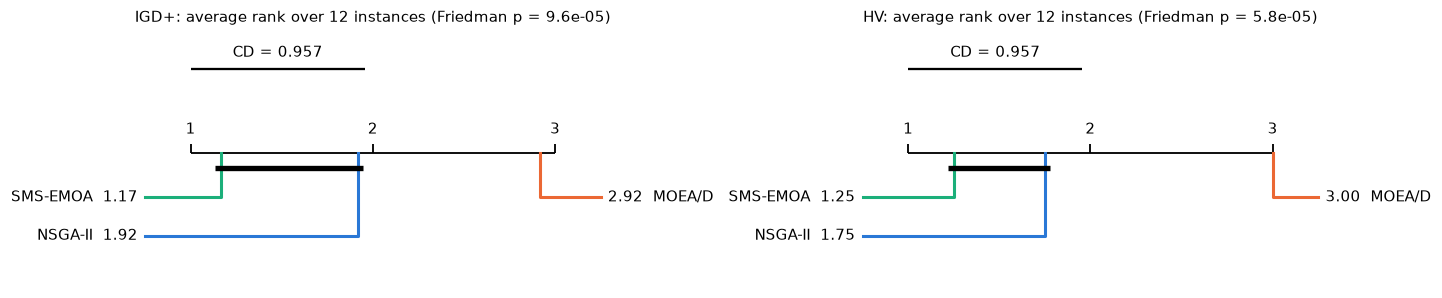

In [10]:
NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728}


def cd_diagram(indicator, lower_is_better, ax):
    median = indicators.groupby(["instance", "algorithm"])[indicator].median().unstack()[ALGORITHMS]
    avg_rank = median.rank(axis=1, ascending=lower_is_better).mean().sort_values()
    k, n = len(avg_rank), len(median)
    cd = NEMENYI_Q05[k] * np.sqrt(k * (k + 1) / (6 * n))
    p = stats.friedmanchisquare(*(median[a] for a in ALGORITHMS)).pvalue

    half = (k + 1) // 2
    ax.set_xlim(0.3, k + 0.7)
    ax.set_ylim(-0.45 - 0.3 * half, 0.95)
    ax.axis("off")
    ax.hlines(0, 1, k, color="black", lw=1.2)
    for r in range(1, k + 1):
        ax.vlines(r, 0, 0.07, color="black", lw=1.2)
        ax.text(r, 0.12, str(r), ha="center", va="bottom")
    ax.hlines(0.65, 1, 1 + cd, color="black", lw=1.5)
    ax.text(1 + cd / 2, 0.72, f"CD = {cd:.3f}", ha="center", va="bottom")
    for i, (alg, r) in enumerate(avg_rank.items()):
        left = i < half
        y = -0.35 - 0.3 * (i if left else k - 1 - i)
        x_end = 0.75 if left else k + 0.25
        ax.plot([r, r, x_end], [0, y, y], color=COLORS[alg], lw=2)
        ax.text(x_end + (-0.04 if left else 0.04), y, f"{alg}  {r:.2f}" if left else f"{r:.2f}  {alg}",
                ha="right" if left else "left", va="center")
    ranks, cliques = avg_rank.to_numpy(), []
    for i in range(k):
        j = max(jj for jj in range(i, k) if ranks[jj] - ranks[i] < cd)
        if j > i and not any(a <= i and j <= b for a, b in cliques):
            cliques.append((i, j))
    for c, (i, j) in enumerate(cliques):
        ax.hlines(-0.12 - 0.09 * c, ranks[i] - 0.03, ranks[j] + 0.03, color="black", lw=3.5)
    ax.set_title(f"{indicator}: average rank over {n} instances (Friedman p = {p:.2g})", fontsize=10)


if len(INSTANCES) >= 2:
    fig, axes = plt.subplots(1, 2, figsize=(13, 2.6), constrained_layout=True)
    cd_diagram("IGD+", True, axes[0])
    cd_diagram("HV", False, axes[1])
    fig.savefig(FIGURES / "pymoo_cd_plots.png", dpi=150)
    plt.show()

## 6. Pareto fronts (Figs. 4–6)

In every panel the **black line** is this notebook's reference front. In Fig. 4 the **dashed grey line** is the paper's published reference front, which also includes SMPSO's solutions. Points are coloured by algorithm.

**Fig. 4 analogue.** For each algorithm, the front of the run with the median HV on AMEX_5_100:

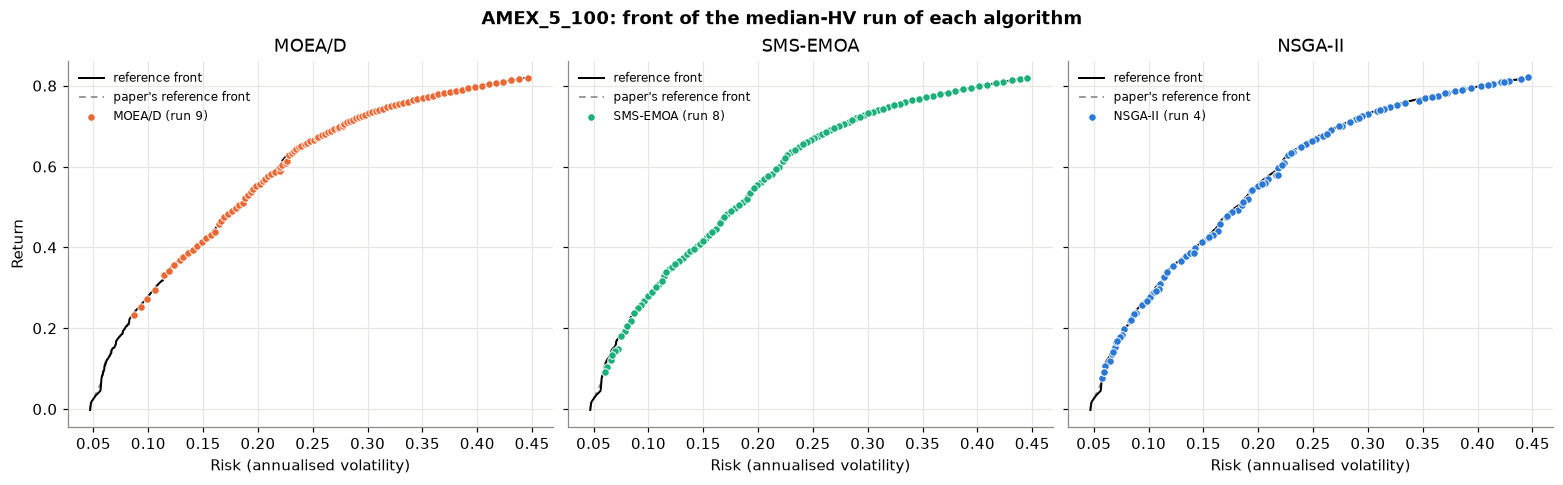

In [11]:
def paper_front(instance):
    pf = np.loadtxt(raw_path(instance, "paper_reference_front"), delimiter=",")
    return pf[np.argsort(pf[:, 0])]


def draw_reference(ax, instance, paper=True):
    rf = ref_front[instance]
    ax.plot(rf[:, 0], -rf[:, 1], color="black", lw=1.3, zorder=2, label="reference front")
    if paper:
        pf = paper_front(instance)
        ax.plot(pf[:, 0], -pf[:, 1], color="#8a8984", lw=1.1, ls=(0, (4, 3)), zorder=1,
                label="paper's reference front")


def median_hv_run(instance, algorithm):
    hv = indicators.query("instance == @instance and algorithm == @algorithm").sort_values("HV")
    return int(hv["run"].iloc[len(hv) // 2])


def front_panels(instance, title):
    fig, axes = plt.subplots(1, len(ALGORITHMS), figsize=(4.7 * len(ALGORITHMS), 4.3),
                             sharex=True, sharey=True, constrained_layout=True)
    for ax, alg in zip(axes, ALGORITHMS):
        ax.set_title(alg)
        ax.set_xlabel("Risk (annualised volatility)")
    axes[0].set_ylabel("Return")
    fig.suptitle(title, fontweight="bold")
    return fig, axes


def plot_median_fronts(instance):
    fig, axes = front_panels(instance, f"{instance}: front of the median-HV run of each algorithm")
    for ax, alg in zip(axes, ALGORITHMS):
        r = median_hv_run(instance, alg)
        F = runs[instance, alg][r][0]
        draw_reference(ax, instance)
        ax.scatter(F[:, 0], -F[:, 1], s=24, color=COLORS[alg], edgecolor="white", linewidth=0.6, zorder=3,
                   label=f"{alg} (run {r})")
        ax.legend(loc="upper left", fontsize=8, frameon=False)
    fig.savefig(FIGURES / f"pymoo_median_fronts_{instance}.png", dpi=150)
    plt.show()


def plot_contributions(instance):
    fig, axes = front_panels(instance, f"Algorithm contributions to the {instance} reference front")
    rf, source = ref_front[instance], ref_source[instance]
    for ax, alg in zip(axes, ALGORITHMS):
        mine = source == alg
        draw_reference(ax, instance, paper=False)
        ax.scatter(rf[mine, 0], -rf[mine, 1], s=16, color=COLORS[alg], edgecolor="white", linewidth=0.25,
                   zorder=3, label=f"{alg}: {mine.sum()} of {len(rf)} points ({mine.mean():.0%})")
        ax.legend(loc="upper left", fontsize=8, frameon=False)
    fig.savefig(FIGURES / f"pymoo_contributions_{instance}.png", dpi=150)
    plt.show()


def pick(instance):
    return instance if instance in INSTANCES else INSTANCES[-1]


plot_median_fronts(pick("AMEX_5_100"))

**Fig. 5 analogue.** Which algorithm found each point of the BATS_5_100 reference front:

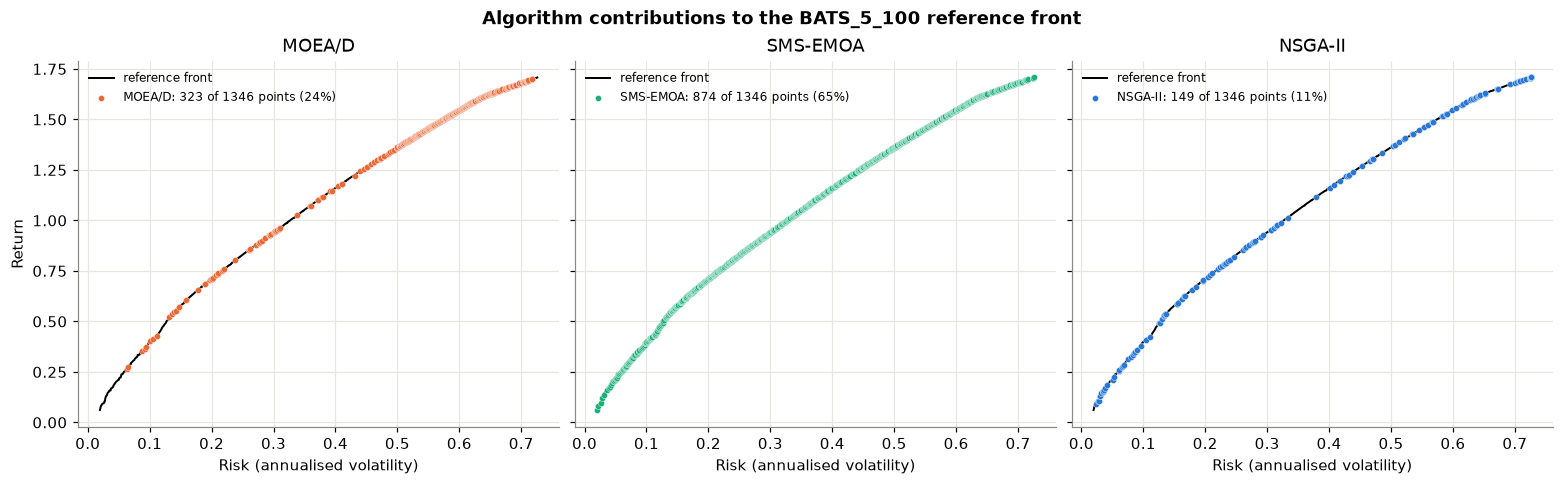

In [12]:
plot_contributions(pick("BATS_5_100"))

**Fig. 6 analogue.** The same for the largest instance, ALL_20_6000:

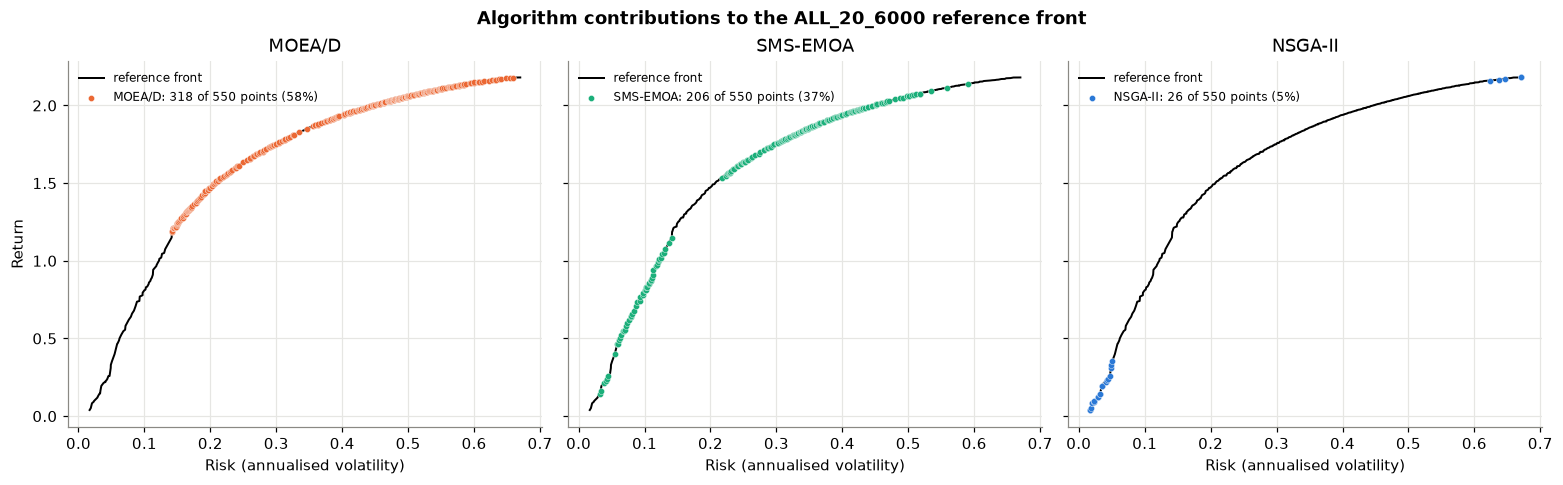

In [13]:
plot_contributions(pick("ALL_20_6000"))

**All instances at a glance.** Every reference front, with each point coloured by the algorithm that found it. Call `plot_median_fronts(...)` or `plot_contributions(...)` with any instance name to get the full-size panels.

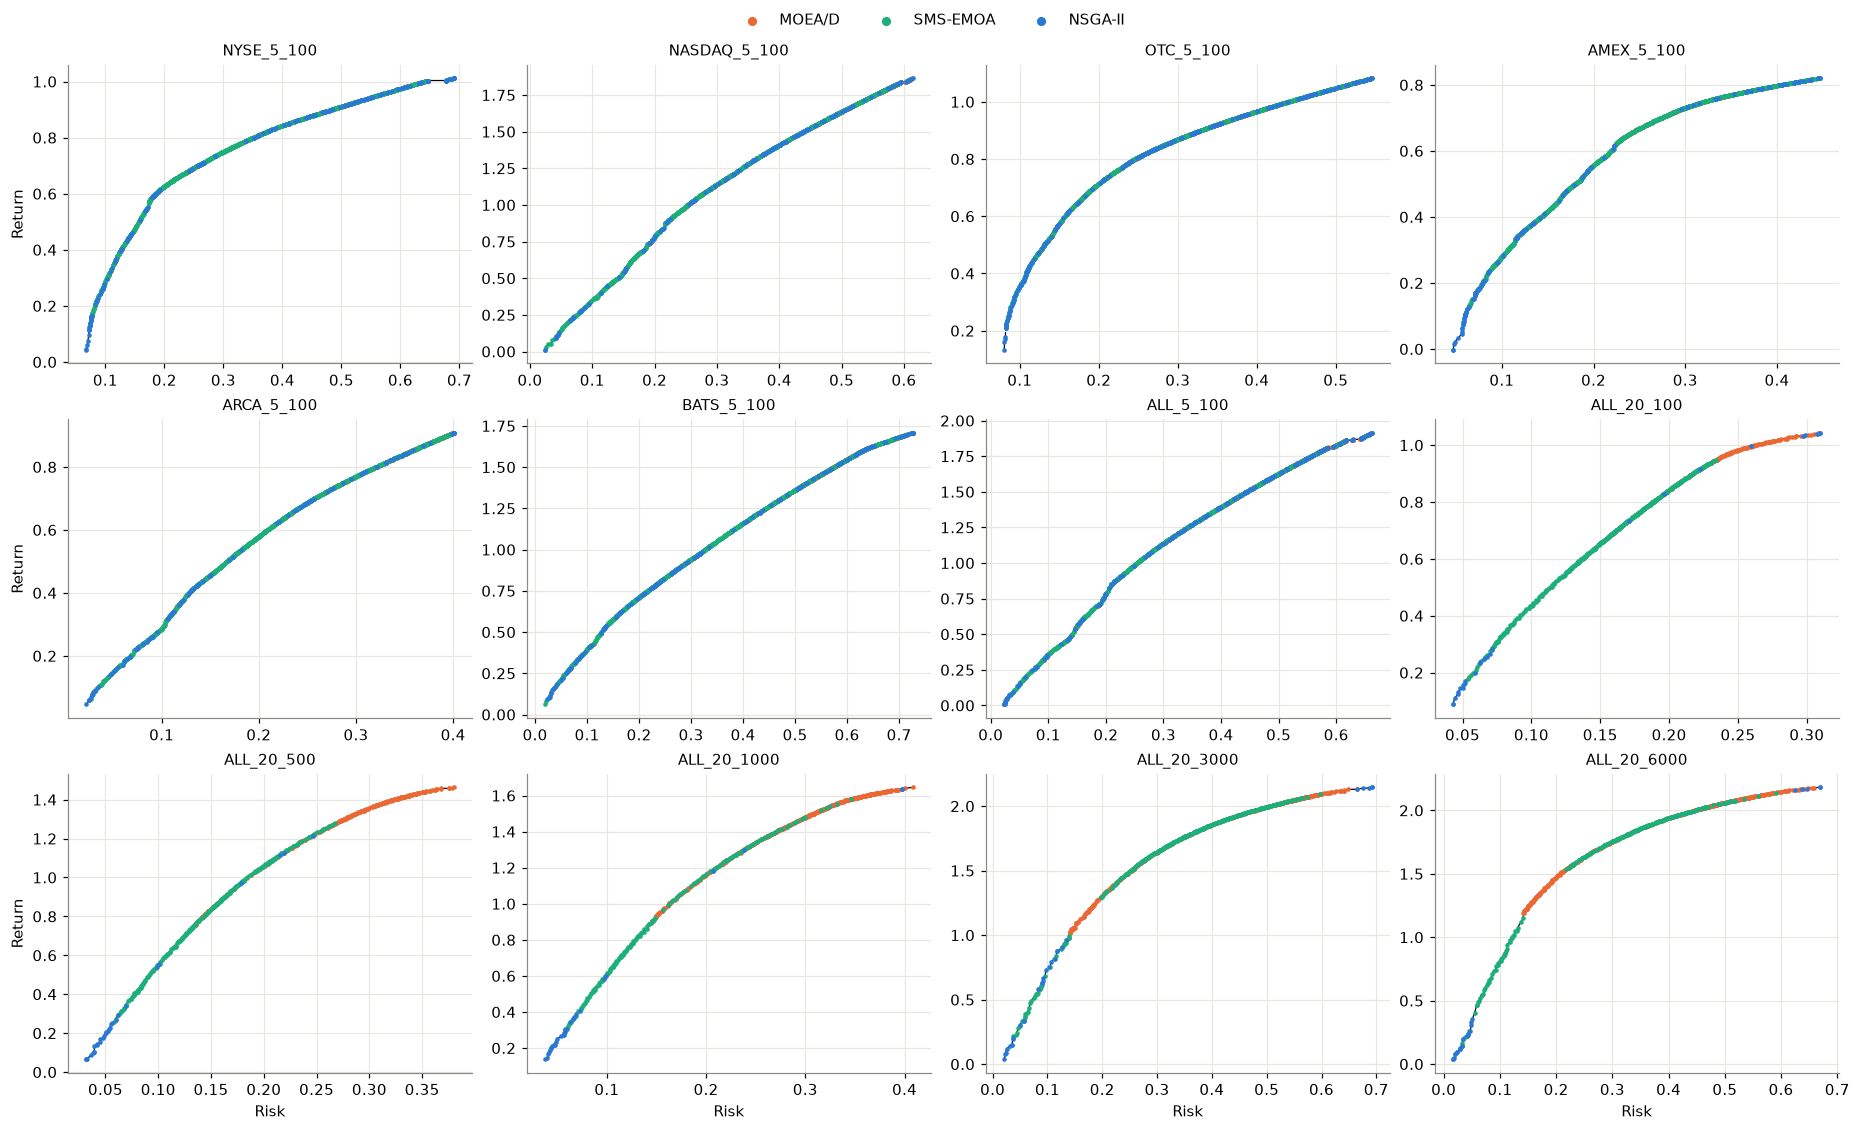

In [14]:
ncols = 4
nrows = int(np.ceil(len(INSTANCES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), constrained_layout=True, squeeze=False)
for ax, inst in zip(axes.flat, INSTANCES):
    rf, source = ref_front[inst], ref_source[inst]
    ax.plot(rf[:, 0], -rf[:, 1], color="black", lw=0.8, zorder=1)
    for alg in ALGORITHMS:
        mine = source == alg
        ax.scatter(rf[mine, 0], -rf[mine, 1], s=9, color=COLORS[alg], linewidth=0, zorder=2, label=alg)
    ax.set_title(inst, fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Risk")
for ax in axes[:, 0]:
    ax.set_ylabel("Return")
for ax in axes.flat[len(INSTANCES):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=len(ALGORITHMS), frameon=False, markerscale=2)
fig.savefig(FIGURES / "pymoo_reference_fronts_all.png", dpi=150)
plt.show()

**Paper vs. replication reference fronts.** For each instance, the reference front the authors published (all runs of their four jMetal algorithms, SMPSO included) and the one built here (all runs of the three pymoo algorithms), on the same axes. Where the two coincide, the thin black line sits inside the grey band.

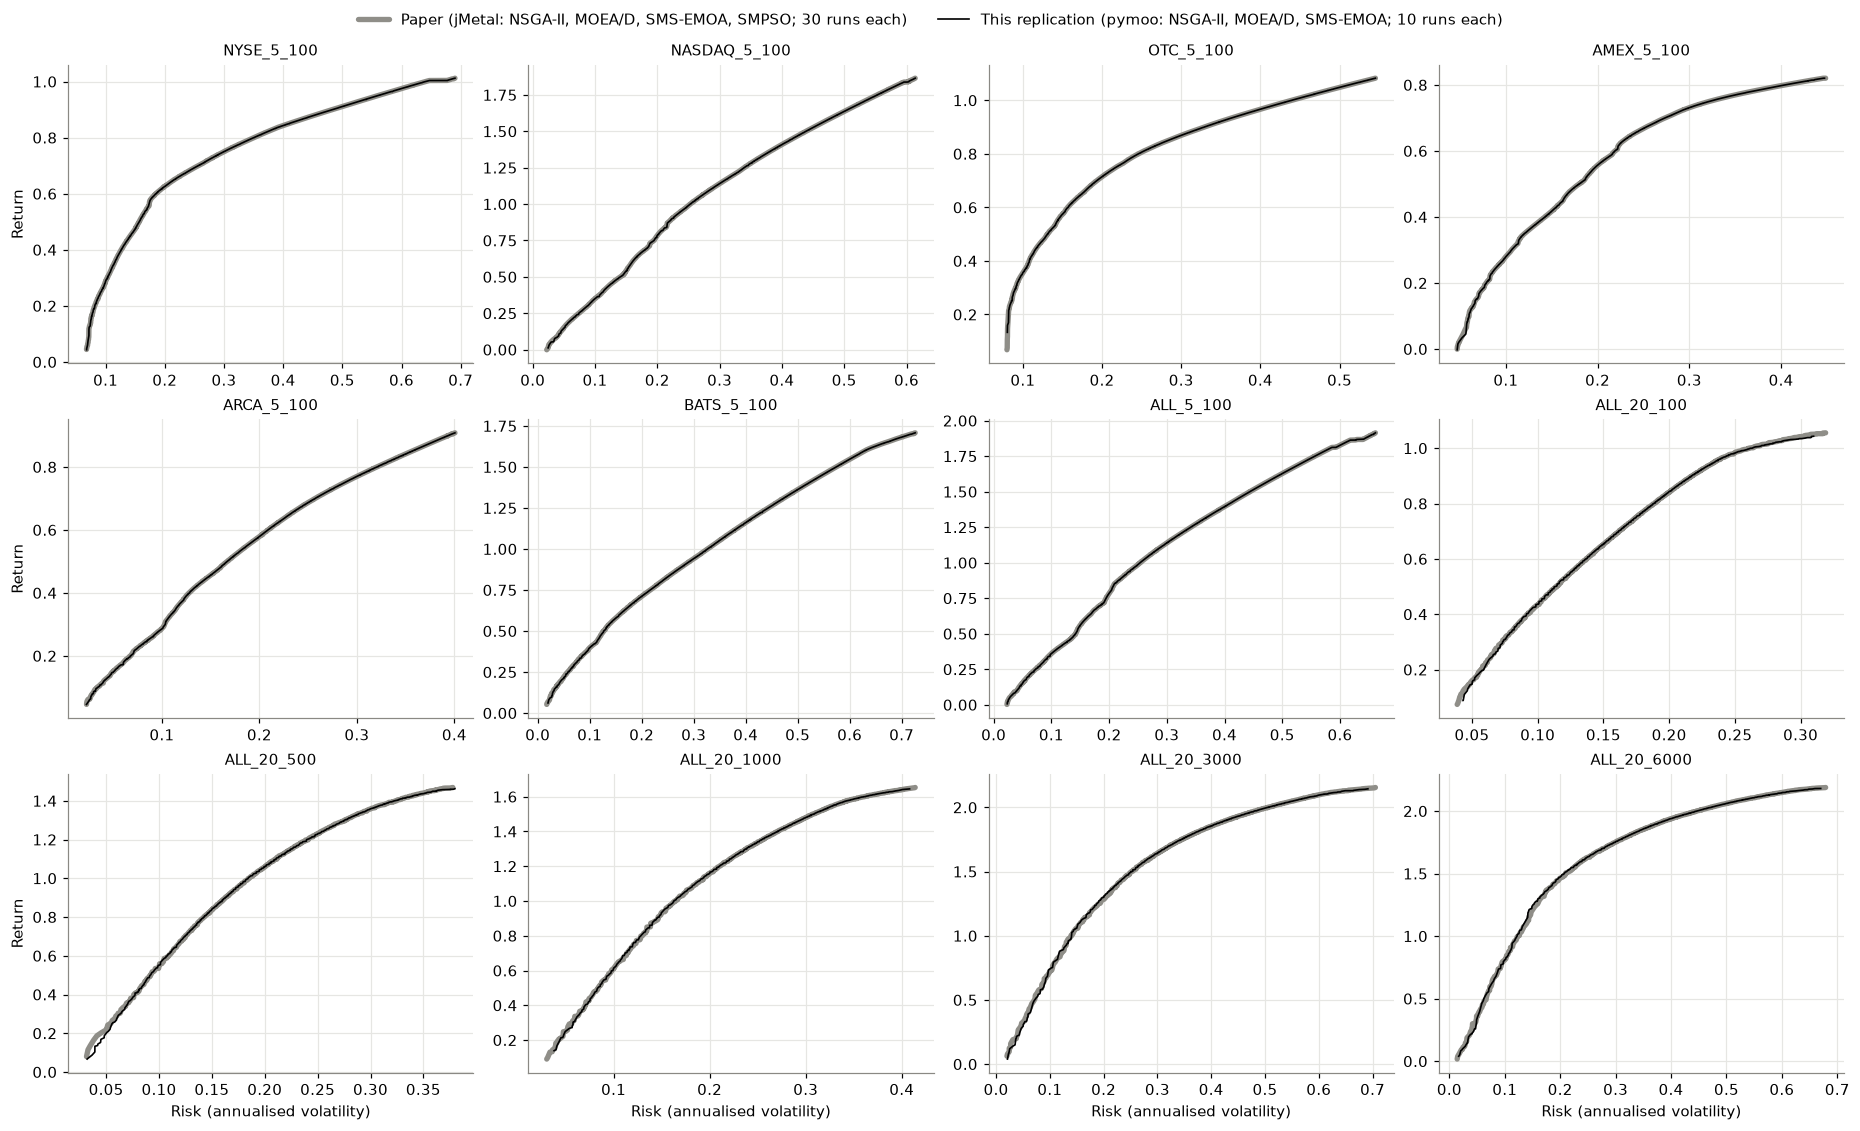

In [15]:
ncols = 4
nrows = int(np.ceil(len(INSTANCES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), constrained_layout=True, squeeze=False)
for ax, inst in zip(axes.flat, INSTANCES):
    pf, rf = paper_front(inst), ref_front[inst]
    ax.plot(pf[:, 0], -pf[:, 1], color="#8f8e88", lw=3.5, solid_capstyle="round",
            label="Paper (jMetal: NSGA-II, MOEA/D, SMS-EMOA, SMPSO; 30 runs each)")
    ax.plot(rf[:, 0], -rf[:, 1], color="black", lw=1.1,
            label=f"This replication (pymoo: NSGA-II, MOEA/D, SMS-EMOA; {N_RUNS} runs each)")
    ax.set_title(inst, fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Risk (annualised volatility)")
for ax in axes[:, 0]:
    ax.set_ylabel("Return")
for ax in axes.flat[len(INSTANCES):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=2, frameon=False)
fig.savefig(FIGURES / "pymoo_vs_paper_reference_fronts.png", dpi=150)
plt.show()

## 7. Representative portfolios (§6.3)

The paper ranks portfolios with the Sharpe ratio $SR = (R_p - R_f)/\sigma_p$, using $R_f = 6.97\,\%$. Below, *Sharpe* is that textbook formula, with $\sigma_p$ the annualised volatility.

The paper's reported **"Fitness"** values match $(R_p - R_f)/\sqrt{\text{Risk}}$ instead. For example, Table 10 gives $(0.2658 - 0.0697)/\sqrt{0.0410} = 0.968$, and Table 11 gives $(1.5672 - 0.0697)/\sqrt{0.2292} = 3.128$. That column is shown as *paper fitness*, so the numbers can be compared directly with Tables 8–14.

For each algorithm, the table pools the final fronts of all its runs and picks three portfolios: the highest return (cf. Table 8), the lowest risk (cf. Table 10) and the best Sharpe ratio (cf. Tables 11, 13 and 14).

In [16]:
PROFILES = {"highest return": ("return", False), "lowest risk": ("risk", True), "best Sharpe": ("Sharpe", False)}


def portfolio_pool(instance):
    parts = []
    for alg in ALGORITHMS:
        for r, (F, X) in enumerate(runs[instance, alg]):
            parts.append(pd.DataFrame({"algorithm": alg, "run": r, "return": -F[:, 1], "risk": F[:, 0], "x": list(X)}))
    df = pd.concat(parts, ignore_index=True)
    df["Sharpe"] = (df["return"] - RISK_FREE) / df["risk"]
    df["paper fitness"] = (df["return"] - RISK_FREE) / np.sqrt(df["risk"])
    return df


def chosen(instance, profile):
    column, ascending = PROFILES[profile]
    pool = portfolio_pool(instance)
    return {alg: g.sort_values(column, ascending=ascending).iloc[0] for alg, g in pool.groupby("algorithm", sort=False)}


def highlights(instance):
    rows = [{"algorithm": alg, "profile": profile, **row[["return", "risk", "Sharpe", "paper fitness"]].to_dict()}
            for profile in PROFILES for alg, row in chosen(instance, profile).items()]
    table = pd.DataFrame(rows).set_index(["profile", "algorithm"])
    return table.style.format({"return": "{:.2%}", "risk": "{:.2%}", "Sharpe": "{:.3f}", "paper fitness": "{:.4f}"}) \
        .set_caption(f"{instance}: representative portfolios (all runs pooled)")


def compositions(instance, profile):
    """Asset weights of the chosen portfolio of each algorithm, side by side."""
    assets = load_instance(instance, with_cov=False)["assets"]
    tables = {}
    for alg, row in chosen(instance, profile).items():
        x = row["x"]
        k = len(x) // 2
        idx = decode_assets(x[None, :k], len(assets))[0]
        t = pd.DataFrame({"asset": [assets[i] for i in idx], "weight": x[k:]})
        t = t.sort_values("weight", ascending=False, ignore_index=True)
        t["weight"] = t["weight"].map("{:.2%}".format)
        tables[f"{alg}: R {row['return']:.1%}, risk {row['risk']:.1%}, Sharpe {row['Sharpe']:.2f}"] = t
    return pd.concat(tables, axis=1).style.set_caption(f"{instance}, {profile} portfolio of each algorithm")


BIG = pick("ALL_20_6000")
display(highlights(BIG))
display(compositions(BIG, "best Sharpe"))

In [17]:
display(compositions(BIG, "lowest risk"))
display(highlights(pick("AMEX_5_100")))
display(compositions(pick("AMEX_5_100"), "highest return"))

## 8. Comparison with the paper

This section was written from the default run: 10 runs per algorithm, seeds 12345–12354. With another `N_RUNS` or seed the exact counts may shift by one or two instances.

| Paper | This replication |
|---|---|
| **IGD+** (Table 4): SMS-EMOA best on all 12 instances, NSGA-II second on 10 | SMS-EMOA best on 10. NSGA-II is best on ALL_20_500 and ALL_20_1000 and second on 9 of the other 10 |
| **HV** (Table 6): SMS-EMOA best on 10, NSGA-II best on ALL_20_100 and ALL_20_500 | SMS-EMOA best on 9, NSGA-II best on ALL_20_100, ALL_20_500 and ALL_20_1000 |
| **CD plots** (Figs. 2–3): SMS-EMOA ranks first, NSGA-II second with no significant difference, MOEA/D behind both | Same order and same conclusion. Average ranks (IGD+ / HV): SMS-EMOA 1.17 / 1.25, NSGA-II 1.92 / 1.75, MOEA/D 2.92 / 3.00; CD = 0.96 |
| **Fig. 4:** MOEA/D converges but misses the extreme regions | Same. MOEA/D's median AMEX_5_100 front starts at risk ≈ 0.09, while the reference front starts at 0.05 |
| **Fig. 5:** SMS-EMOA contributes most to the BATS_5_100 front | Same: 65 % of the points (MOEA/D 24 %, NSGA-II 11 %) |
| **Fig. 6:** on ALL_20_6000, NSGA-II covers the low-risk end, SMS-EMOA and MOEA/D the centre, and only SMPSO the high-return end | NSGA-II again has the low-risk end and MOEA/D and SMS-EMOA the centre. Here, though, the GAs also reach the high-return end |
| **Table 8:** highest return on ALL_20_6000 is 218.85 % at 67.89 % risk (SMPSO) | About 218 % at 66–68 % risk, found by all three algorithms |
| **Table 9:** AMEX_5_100 high-return portfolio is ARMP, ACU, BRIA, DSS, GAU (SMPSO) | The same five assets, with ARMP at the 40 % cap |
| **Tables 11, 13, 14:** best fitness on ALL_20_6000 is 3.1280 (NSGA-II), 3.1315 (SMS-EMOA), 3.1368 (MOEA/D) | Best *paper fitness* is 3.1039 (NSGA-II), 3.1412 (SMS-EMOA), 3.1534 (MOEA/D). The best-Sharpe portfolios share many tickers with those tables: GEOS, GREEL, ANG.PRB, ELTK, MATH, IRON, KOLD, CASK, GYRE, AAOI, … |

**Main difference.** In the paper only SMPSO reaches the high-risk, high-return end of the fronts. Here the three evolutionary algorithms reach it too. The merged reference fronts cover the same risk range as the paper's four-algorithm fronts (dashed line in the Fig. 4 analogue).

**Not comparable.** Absolute HV values differ from Table 6 (about 0.75–0.95 here, against 0.57–0.74 there). The reference fronts are different, since the paper's includes SMPSO, and the paper does not say exactly how its reference point is normalised. Rankings and statistical tests are the meaningful comparison.